# Prática de EDA: Spotify Songs

**Aluno:** Pedro Abner Saboya Tavares di Cavalcanti Garcez
**Disciplina:** Análise e Visualização de Dados (AVD), 2026.2

Esta EDA replica o ciclo feito em sala com o *Heart Disease* (Aula 11), agora aplicado ao dataset **Spotify Songs**: cerca de 30 mil músicas coletadas de playlists do Spotify em seis gêneros (edm, latin, pop, r&b, rap e rock), com as características de áudio calculadas pela API do Spotify.

- **Fonte:** projeto TidyTuesday (2020-01-21), dados extraídos com o pacote `spotifyr`: https://github.com/rfordatascience/tidytuesday/tree/master/data/2020/2020-01-21
- **Pergunta que guia a análise:** o que diferencia, nas características de áudio, as músicas **populares** das **não populares**?

Assim como na aula, a EDA é **iterativa**: olhamos a estatística descritiva **antes** de tratar ausentes e outliers (para saber *como* tratar) e **depois** (para confirmar o efeito do tratamento).

## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [2]:
# Spotify Songs (TidyTuesday 2020-01-21)
DATA_URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv"

df = pd.read_csv(DATA_URL)
df.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o dataset tem identificadores (música, álbum, playlist), metadados em texto (nome, artista, data de lançamento, gênero e subgênero da playlist), a popularidade (0 a 100) e 12 características de áudio. Como as músicas foram coletadas *a partir de playlists*, a expectativa é de dezenas de milhares de linhas, e de que a mesma música possa aparecer em mais de uma playlist.

### Dimensão e Tipos de Dados

In [3]:
df.shape

(32833, 23)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  str    
 1   track_name                32828 non-null  str    
 2   track_artist              32828 non-null  str    
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  str    
 5   track_album_name          32828 non-null  str    
 6   track_album_release_date  32833 non-null  str    
 7   playlist_name             32833 non-null  str    
 8   playlist_id               32833 non-null  str    
 9   playlist_genre            32833 non-null  str    
 10  playlist_subgenre         32833 non-null  str    
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudness         

In [5]:
df.describe()

,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000
mean,42.477081,0.654850,0.698619,5.374471,-6.719499,0.565711,0.107068,0.175334,0.084747,0.190176,0.510561,120.881132,225799.811622
std,24.984074,0.145085,0.180910,3.611657,2.988436,0.495671,0.101314,0.219633,0.224230,0.154317,0.233146,26.903624,59834.006182
min,0.000000,0.000000,0.000175,0.000000,-46.448000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000.000000
25%,24.000000,0.563000,0.581000,2.000000,-8.171000,0.000000,0.041000,0.015100,0.000000,0.092700,0.331000,99.960000,187819.000000
50%,45.000000,0.672000,0.721000,6.000000,-6.166000,1.000000,0.062500,0.080400,0.000016,0.127000,0.512000,121.984000,216000.000000
75%,62.000000,0.761000,0.840000,9.000000,-4.645000,1.000000,0.132000,0.255000,0.004830,0.248000,0.693000,133.918000,253585.000000
max,100.000000,0.983000,1.000000,11.000000,1.275000,1.000000,0.918000,0.994000,0.994000,0.996000,0.991000,239.440000,517810.000000


**Leitura:** são 32.833 linhas e 23 colunas. As colunas numéricas estão com o tipo certo (`int64`/`float64`) e as de texto como objeto/string. Dois pontos de atenção:

- `key` (tom, 0 a 11) e `mode` (0 = menor, 1 = maior) são numéricas no arquivo, mas representam **categorias**. Vão para o grupo das qualitativas.
- `track_album_release_date` está como texto e com precisões diferentes (data completa ou só o ano). Só vamos precisar do **ano**, que extraímos mais à frente.

### Duplicadas

In [6]:
df.duplicated().sum()

np.int64(0)

Nenhuma linha é idêntica a outra. Porém, cada linha aqui é "uma música **dentro de uma playlist**", então a mesma música pode se repetir com `playlist_name`/`playlist_id` diferentes. Vale checar duplicidade pelo identificador da música:

In [7]:
print("track_id repetidos:", df["track_id"].duplicated().sum())

# As repetições são a mesma música (mesmas características de áudio e mesma popularidade)?
cols_musica = ["track_popularity", "danceability", "energy", "loudness", "speechiness", "acousticness",
               "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]
variacao = df[df["track_id"].duplicated(keep=False)].groupby("track_id")[cols_musica].nunique()
print("Músicas repetidas com algum valor diferente entre as cópias:", (variacao > 1).any(axis=1).sum())

track_id repetidos: 4477
Músicas repetidas com algum valor diferente entre as cópias: 0


**Decisão:** 4.477 linhas repetem um `track_id`, e em todas as cópias as características de áudio e a popularidade são **idênticas**. Ou seja, é a mesma música contada várias vezes só porque está em várias playlists. Como a nossa unidade de análise é a **música**, manter as cópias daria peso extra às músicas que aparecem em mais playlists e distorceria as distribuições. Mantemos **uma linha por `track_id`** (a primeira ocorrência, com o gênero da primeira playlist em que a música aparece).

In [8]:
linhas_antes_dup = df.shape[0]
df = df.drop_duplicates(subset="track_id").reset_index(drop=True)
print(f"Linhas antes: {linhas_antes_dup} | Linhas depois: {df.shape[0]} | Removidas: {linhas_antes_dup - df.shape[0]}")

Linhas antes: 32833 | Linhas depois: 28356 | Removidas: 4477


### Renomeando o atributo alvo para facilitar a interpretação

O dataset registra `track_popularity` de 0 a 100. Assim como na aula (em que `num` virou "Normal"/"Cardíaco"), vamos criar uma variável **binária** para usar nas cores ao longo da análise (rosa = não popular, roxo = popular):

- **Popular:** músicas no quartil superior de popularidade (`track_popularity` ≥ Q3);
- **Não popular:** as demais.

Diferente da aula, **não excluímos** a coluna original: `track_popularity` é a métrica de negócio do dataset e continua útil como número. Ela só não entra na lista de variáveis quantitativas analisadas, porque é a origem do alvo, assim como `num` não entrava na aula.

In [9]:
LIMIAR_POPULAR = df["track_popularity"].quantile(0.75)
print("Limiar (Q3) de popularidade:", LIMIAR_POPULAR)

df["popularidade_classe"] = np.where(df["track_popularity"] >= LIMIAR_POPULAR, "Popular", "Não popular")
df["popularidade_classe"].value_counts()

Limiar (Q3) de popularidade: 58.0


popularidade_classe
Não popular    21088
Popular         7268
Name: count, dtype: int64

## 2. Dados Faltantes

In [10]:
df.isna().sum()

track_id                    0
track_name                  4
track_artist                4
track_popularity            0
track_album_id              0
track_album_name            4
track_album_release_date    0
playlist_name               0
playlist_id                 0
playlist_genre              0
playlist_subgenre           0
danceability                0
energy                      0
key                         0
loudness                    0
mode                        0
speechiness                 0
acousticness                0
instrumentalness            0
liveness                    0
valence                     0
tempo                       0
duration_ms                 0
popularidade_classe         0
dtype: int64

**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Sim, mas pouquíssimos. Apenas `track_name`, `track_artist` e `track_album_name` têm ausentes, 4 em cada uma (de ~28 mil músicas). Todas as características de áudio e a popularidade estão completas.

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos três features com dados ausentes, todas de **metadados em texto**:

* `track_name`: nome da música
* `track_artist`: artista
* `track_album_name`: nome do álbum

*Como os dados foram coletados:*
- Os dados foram extraídos da API do Spotify com o pacote `spotifyr`: buscaram-se playlists por gênero/subgênero e, de cada playlist, as músicas e suas características de áudio.

*Qual a natureza da fonte de dados:*
- As características de áudio vêm de uma análise automática do arquivo de áudio; já os metadados vêm do catálogo. Uma música pode continuar na playlist e ter o áudio analisado mesmo depois que o catálogo deixou de exibir seus dados (por exemplo, por remoção ou mudança de licença).

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático.

In [11]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())

Colunas com ausentes: ['track_name', 'track_artist', 'track_album_name']
track_name          4
track_artist        4
track_album_name    4
dtype: int64


Com poucos ausentes, uma correlação entre os indicadores de ausência seria calculada em cima de pouquíssimos casos. Assim como na aula, a contagem bruta (quantas linhas têm as ausências ao mesmo tempo) é mais honesta.

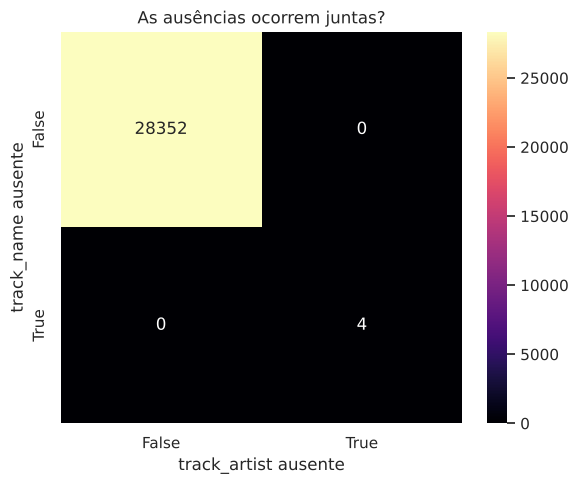

,track_id,track_popularity,playlist_genre,danceability,tempo
7668,69gRFGOWY9OMpFJgFol1u0,0,rap,0.714,95.999
8692,5cjecvX0CmC9gK0Laf5EMQ,0,rap,0.678,146.153
8693,5TTzhRSWQS4Yu8xTgAuq6D,0,rap,0.465,86.839
17665,3VKFip3OdAvv4OfNTgFWeQ,0,latin,0.675,97.017


In [12]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

# E as linhas com ausência têm algo em comum nas variáveis observadas?
df[df[cols_com_ausentes].isna().any(axis=1)][["track_id", "track_popularity", "playlist_genre", "danceability", "tempo"]]

**Pra discutir:** quantas linhas têm as colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR)?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

*Resposta:* as 4 linhas têm **as três colunas ausentes ao mesmo tempo**. Não são três falhas independentes, é um único evento: o registro da música ficou sem metadados no catálogo. E as 4 têm **popularidade 0**, enquanto o áudio delas está completo e normal.

- Isso afasta o **MCAR** puro: a ausência não está espalhada ao acaso, ela se concentra em músicas com popularidade 0.
- Também não parece **MNAR**: o nome de uma música não "causa" a sua própria ausência.
- A hipótese mais provável é **MAR**: a ausência depende de outra variável observada (popularidade 0, compatível com faixas que saíram do catálogo).

Como na aula, sem falar com quem coletou os dados não dá para cravar o mecanismo, mas o volume (4 linhas, ~0,01%) torna o risco de viés desprezível.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção.

In [13]:
VARS_QUANT = ["danceability", "energy", "loudness", "speechiness", "acousticness",
              "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]
VARS_QUALI = ["playlist_genre", "playlist_subgenre", "key", "mode"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
danceability,0.65,0.67,0.15,0.00,0.98,-0.51,0.02
energy,0.70,0.72,0.18,0.00,1.00,-0.65,-0.01
loudness,-6.82,-6.26,3.04,-46.45,1.27,-1.36,4.58
speechiness,0.11,0.06,0.10,0.00,0.92,1.96,4.27
acousticness,0.18,0.08,0.22,0.00,0.99,1.58,1.78
instrumentalness,0.09,0.00,0.23,0.00,0.99,2.62,5.49
liveness,0.19,0.13,0.16,0.00,1.00,2.08,5.08
valence,0.51,0.51,0.23,0.00,0.99,-0.01,-0.91
tempo,120.96,121.99,26.95,0.00,239.44,0.51,0.08
duration_ms,226575.97,216933.00,61078.45,4000.00,517810.00,1.12,2.54


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1 em módulo) ou com cauda pesada (`kurtosis` maior que 2 em módulo)? Isso é coerente com o que esperaríamos do domínio?

*Resposta:*
- **Assimetria à direita forte:** `instrumentalness` (2,6), `liveness` (2,1), `speechiness` (2,0), `acousticness` (1,6) e `duration_ms` (1,1). Faz sentido: a maioria das músicas desses gêneros é cantada, gravada em estúdio e pouco acústica. Esses atributos ficam perto de 0 para quase todas, e só alguns casos (faixas instrumentais, gravações ao vivo, rap muito falado) puxam a cauda.
- **Assimetria à esquerda:** `loudness` (-1,4), com cauda pesada (curtose 4,6). A produção comercial é masterizada perto do volume máximo (0 dB), então os valores se acumulam entre -8 e -4 dB, e poucas faixas muito baixas formam a cauda.
- **Quase simétricas:** `valence` (~0) e `tempo` (0,5). `danceability` e `energy` são levemente assimétricas à esquerda.
- O mínimo de `tempo` é **0 BPM** e o de `duration_ms` fica em poucos segundos. Esses valores merecem investigação na Seção 4.

### Distribuições de dados

Onde fizer sentido, comparamos "Não popular" (rosa) vs. "Popular" (roxo). Vamos manter essa convenção de cor até a análise bivariada.

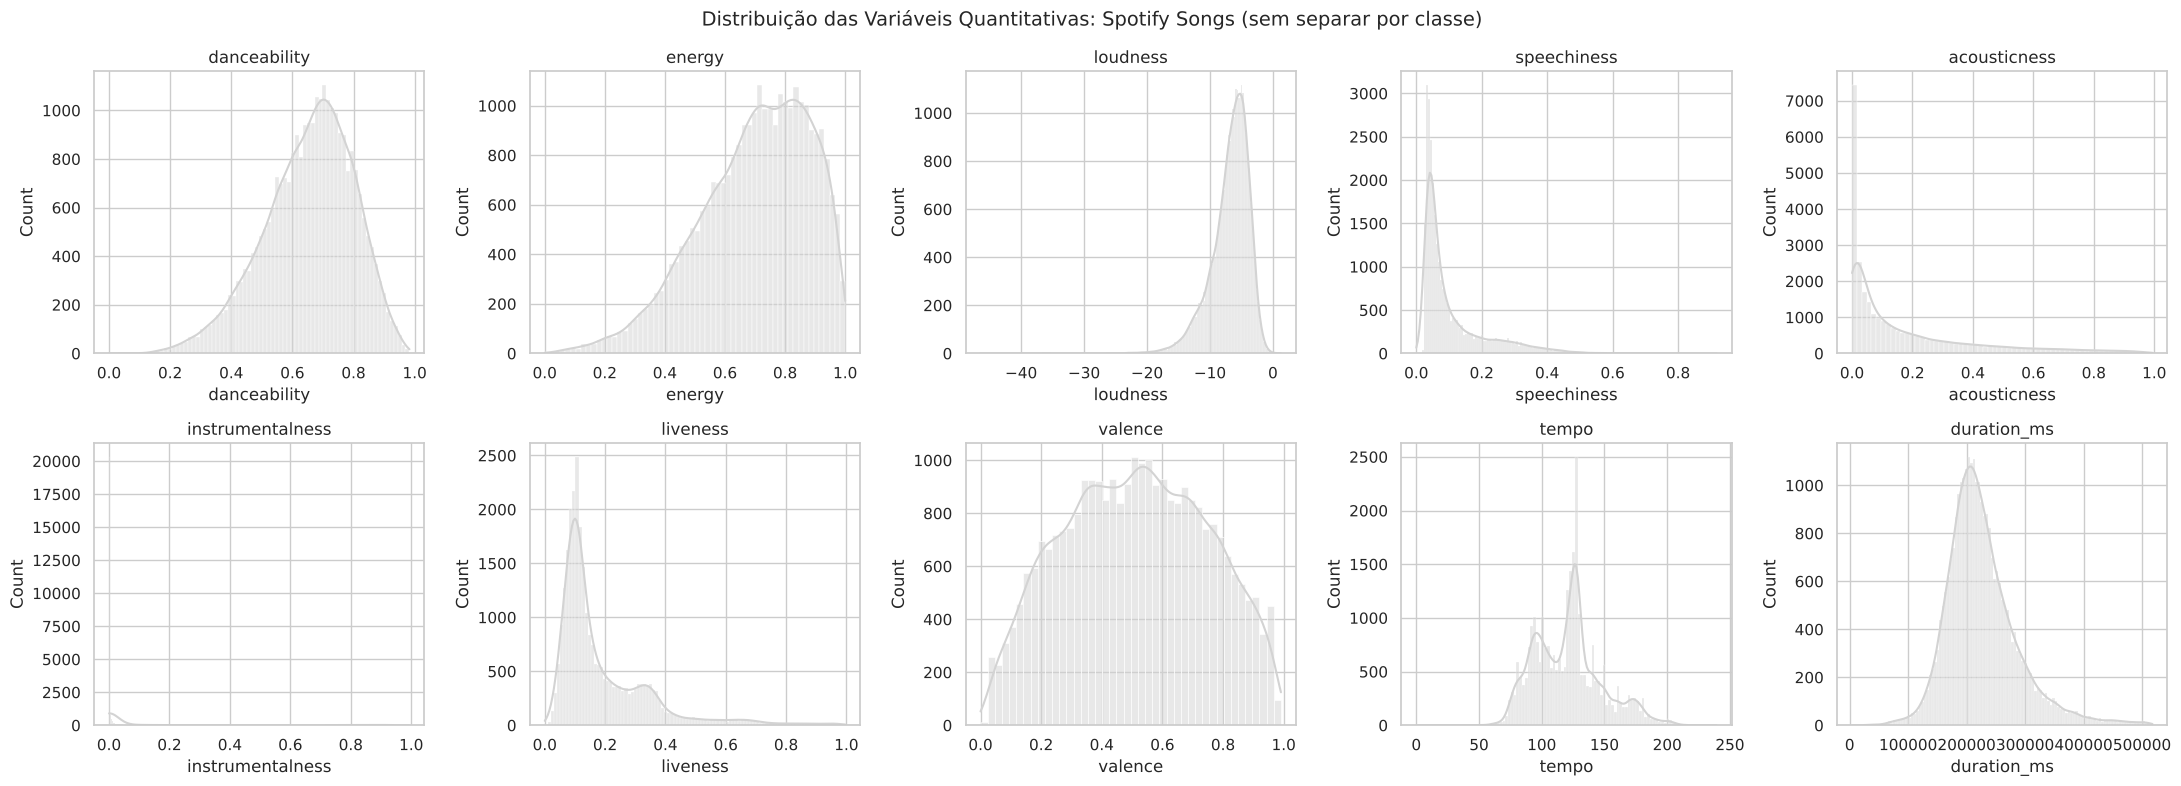

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Spotify Songs (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

*Nota:* diferente da aula, aqui **não** usamos `sharey=True`. As variáveis têm escalas de contagem muito diferentes (`instrumentalness` tem dezenas de milhares de zeros), e um eixo Y compartilhado achataria os demais histogramas.

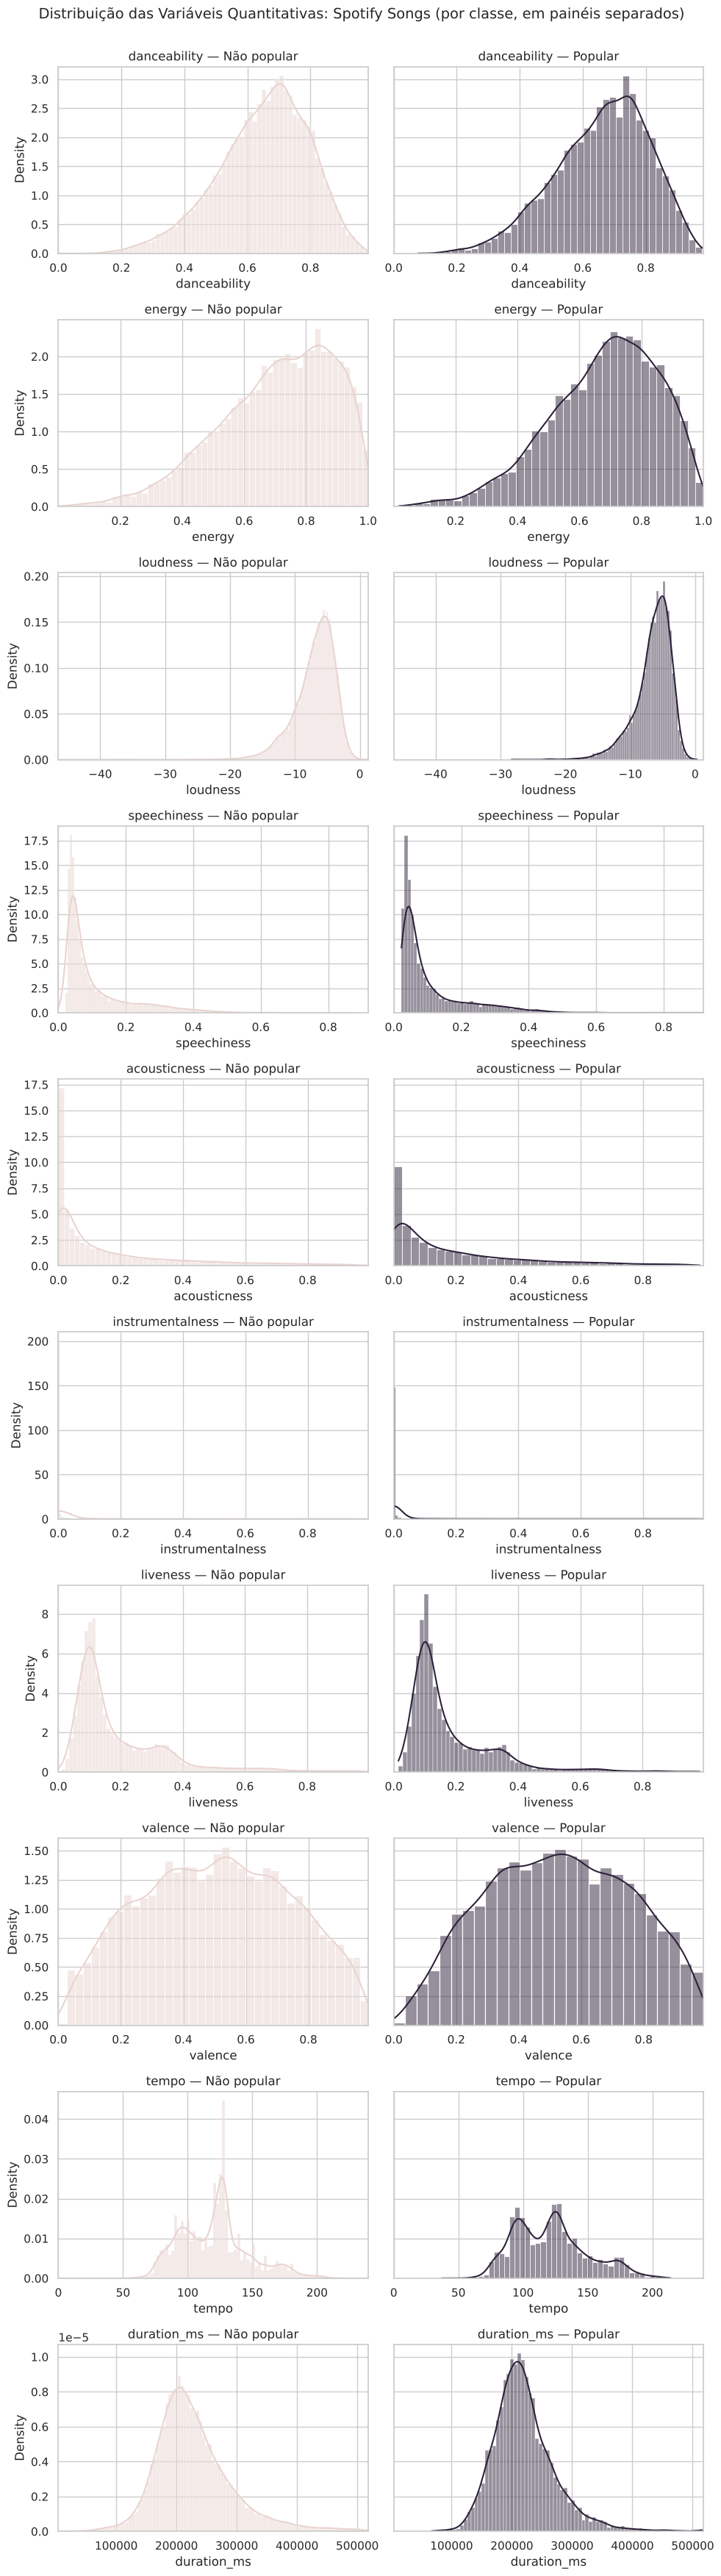

In [15]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey="row")

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Não popular", COR_CONTEXTO), ("Popular", COR_DESTAQUE)]):
        subset = df[df["popularidade_classe"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, stat="density", ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Spotify Songs (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

*Nota:* usamos `stat="density"` porque as classes têm tamanhos diferentes (~74% x ~26%). Com contagem bruta, a classe "Popular" pareceria sempre menor e o que importa aqui é o **formato**.

**Para discutir:** alguma variável parece ter formato bem diferente entre "Não popular" e "Popular"?

*Resposta:* os formatos são parecidos na maioria das variáveis. As diferenças mais visíveis estão em `energy`, em que o pico das não populares fica perto de 0,85 e o das populares perto de 0,75, e em `acousticness`, em que as populares têm menos músicas coladas no zero. Em `instrumentalness` o histograma fica ilegível nas duas classes, porque quase todos os valores estão em ~0. Essa variável fica mais clara nos boxplots abaixo. Não há nenhuma variável que separe as classes sozinha.

#### Testes de Aderência

*Será que a duração das músicas segue uma distribuição normal?*

Usamos o **Shapiro-Wilk** junto com o **QQ-Plot**, testando com `duration_ms`, o equivalente ao `chol` da aula: uma medida contínua, com leve assimetria e alguns valores extremos.

*Adaptação:* o Shapiro-Wilk do `scipy` só garante p-valor preciso até N = 5.000, e temos ~28 mil músicas. Rodamos o teste em uma **amostra aleatória de 5.000** (com semente fixa para reprodutibilidade). O QQ-Plot usa todos os dados.

Shapiro-Wilk — duration_ms: estatística=0.9382, p-valor=1.848e-41
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


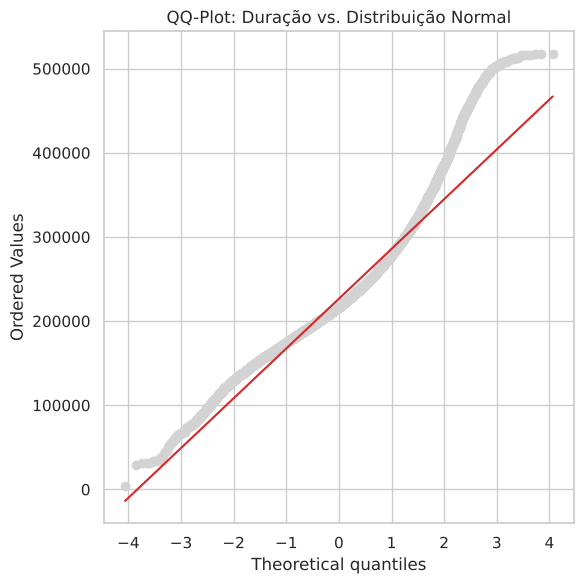

In [16]:
amostra_sw = df.sample(5000, random_state=42)

stat_sw, p_valor_sw = stats.shapiro(amostra_sw["duration_ms"].dropna())
print(f"Shapiro-Wilk — duration_ms: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["duration_ms"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Duração vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos seguissem a reta vermelha de perto, a variável seguiria uma normal. Em `duration_ms`, os pontos se afastam da reta nas duas pontas, principalmente na direita (músicas longas). Isso indica cauda mais pesada que a normal e é coerente com o Shapiro-Wilk.

**Sobre o tamanho da amostra:** como discutido em sala, amostras muito grandes deixam o teste sensível demais e rejeitam por desvios triviais. Mesmo com 5.000 linhas, o teste tem muito poder. Por isso não usamos o teste sozinho: assimetria, QQ-Plot e Shapiro-Wilk concordam. Como o teste **rejeita** H0, a afirmação correta é "temos evidência estatística **contra** a normalidade".

In [17]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(amostra_sw[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": p, "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
danceability,0.9825,2.177298e-24,True
energy,0.9629,5.684441e-34,True
loudness,0.9310,3.524131e-43,True
speechiness,0.7520,1.008639e-65,True
acousticness,0.7861,7.252515e-63,True
instrumentalness,0.4384,1.108871e-82,True
liveness,0.7739,6.299139e-64,True
valence,0.9795,2.698823e-26,True
tempo,0.9760,3.079115e-28,True


Nenhuma das 10 variáveis passa no teste de normalidade. Isso vai guiar a escolha de **Spearman** na correlação e de testes **não-paramétricos** na análise bivariada.

**ECDF: outra forma de ver a distribuição**

Para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. Ilustramos com uma única variável (`duration_ms`).

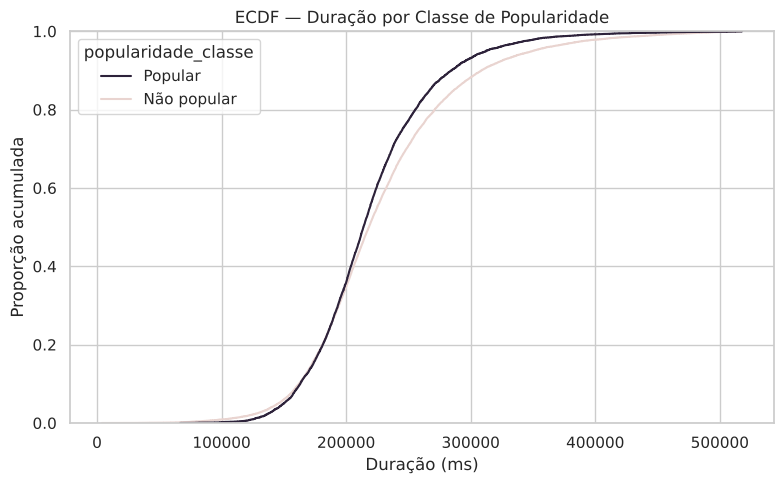

In [18]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="duration_ms", hue="popularidade_classe",
             palette={"Não popular": COR_CONTEXTO, "Popular": COR_DESTAQUE})
plt.title("ECDF — Duração por Classe de Popularidade")
plt.xlabel("Duração (ms)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração das músicas desse grupo dura até aqui". A curva roxa (Popular) fica levemente acima da rosa na faixa de ~3 a ~4 minutos (180 a 240 mil ms), então as populares tendem a ser um pouco mais curtas. A diferença é pequena e as curvas se juntam nas pontas.

### Métricas de Tendêncial Central

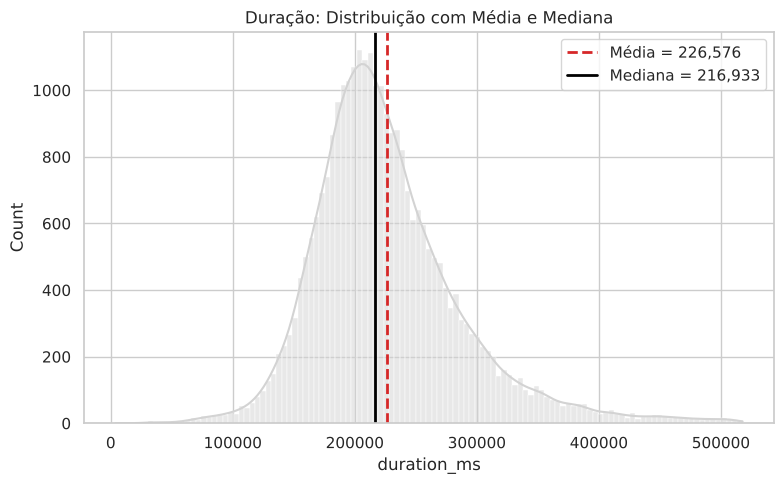

In [19]:
media_dur = df["duration_ms"].mean()
mediana_dur = df["duration_ms"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="duration_ms", kde=True, color=COR_NEUTRA)
plt.axvline(media_dur, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_dur:,.0f}")
plt.axvline(mediana_dur, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_dur:,.0f}")
plt.title("Duração: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

A média (~3min47s) fica à direita da mediana (~3min37s), puxada pela cauda de músicas longas. É o comportamento esperado de uma distribuição com assimetria positiva, e a mediana representa melhor a "música típica".

### Dispersão

In [20]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

,var,std,IQR
danceability,2.000000e-02,0.15,0.20
energy,3.000000e-02,0.18,0.26
loudness,9.220000e+00,3.04,3.60
speechiness,1.000000e-02,0.10,0.09
acousticness,5.000000e-02,0.22,0.25
instrumentalness,5.000000e-02,0.23,0.01
liveness,2.000000e-02,0.16,0.16
valence,5.000000e-02,0.23,0.37
tempo,7.265500e+02,26.95,34.03
duration_ms,3.730577e+09,61078.45,67233.25


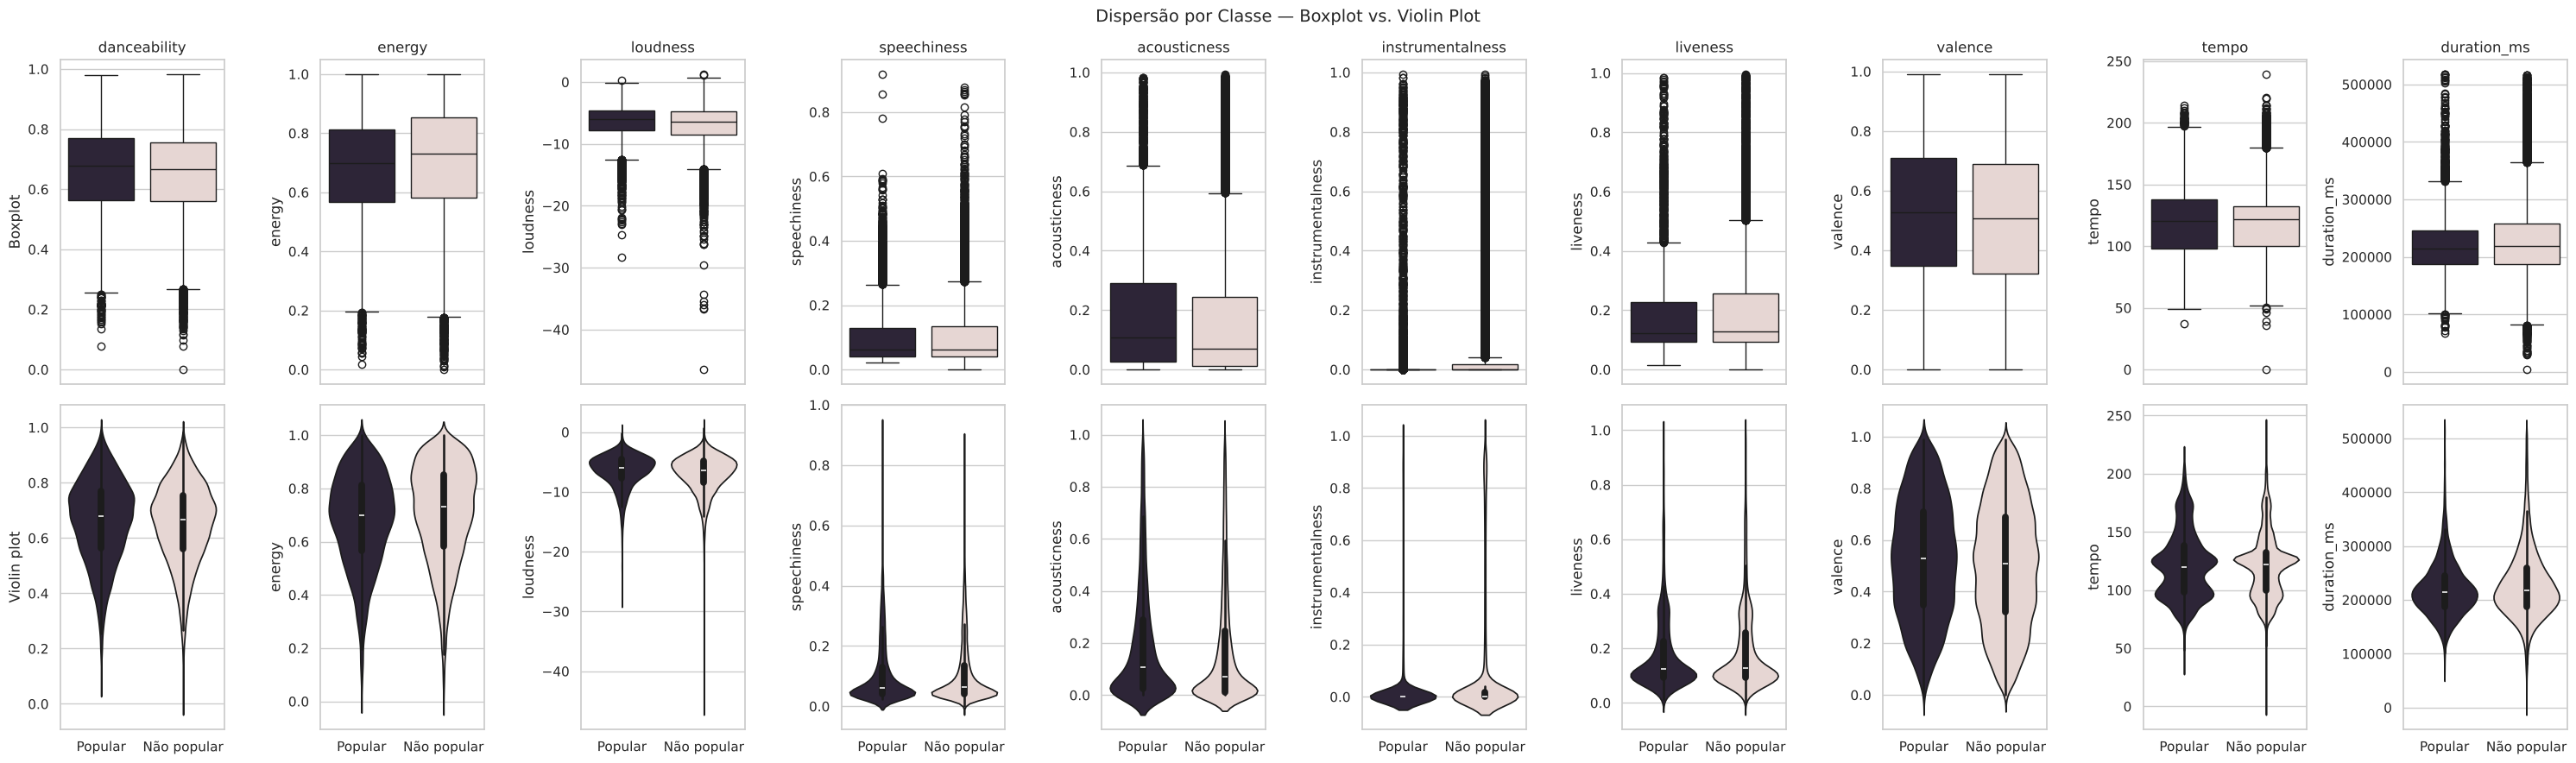

In [21]:
palette_classe = {"Não popular": COR_CONTEXTO, "Popular": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(3 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="popularidade_classe", y=col, hue="popularidade_classe",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="popularidade_classe", y=col, hue="popularidade_classe",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Não popular" e "Popular"?

*Resposta:* nenhuma caixa se separa nitidamente. As diferenças são de deslocamento leve: as populares têm `energy` um pouco menor, `loudness` um pouco maior (mais alto) e `acousticness` um pouco maior. Em `instrumentalness` a caixa é praticamente um traço no zero para as duas classes. O violin mostra bem que essa variável é quase toda zero, com uma cauda longa. Já há aqui um indício de que **as características de áudio, isoladas, explicam pouco da popularidade**.

## 4. Tratamento de Dados Ausentes e Outliers

Com o retrato "antes" da Seção 3, temos a informação que faltava para decidir como tratar tanto os ausentes (`track_name`, `track_artist`, `track_album_name`) quanto os outliers das variáveis quantitativas. Depois do tratamento, rodamos a descritiva de novo ("depois").

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [22]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 3),
        "limite_superior": round(lim_sup, 3),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
danceability,0.263,1.058,257.0
energy,0.183,1.239,222.0
loudness,-13.710,0.691,837.0
speechiness,-0.097,0.271,2725.0
acousticness,-0.354,0.628,1911.0
instrumentalness,-0.010,0.016,6085.0
liveness,-0.142,0.484,1623.0
valence,-0.220,1.244,0.0
tempo,48.931,185.040,494.0
duration_ms,86892.125,355825.125,1197.0


### Visualizando os Outliers

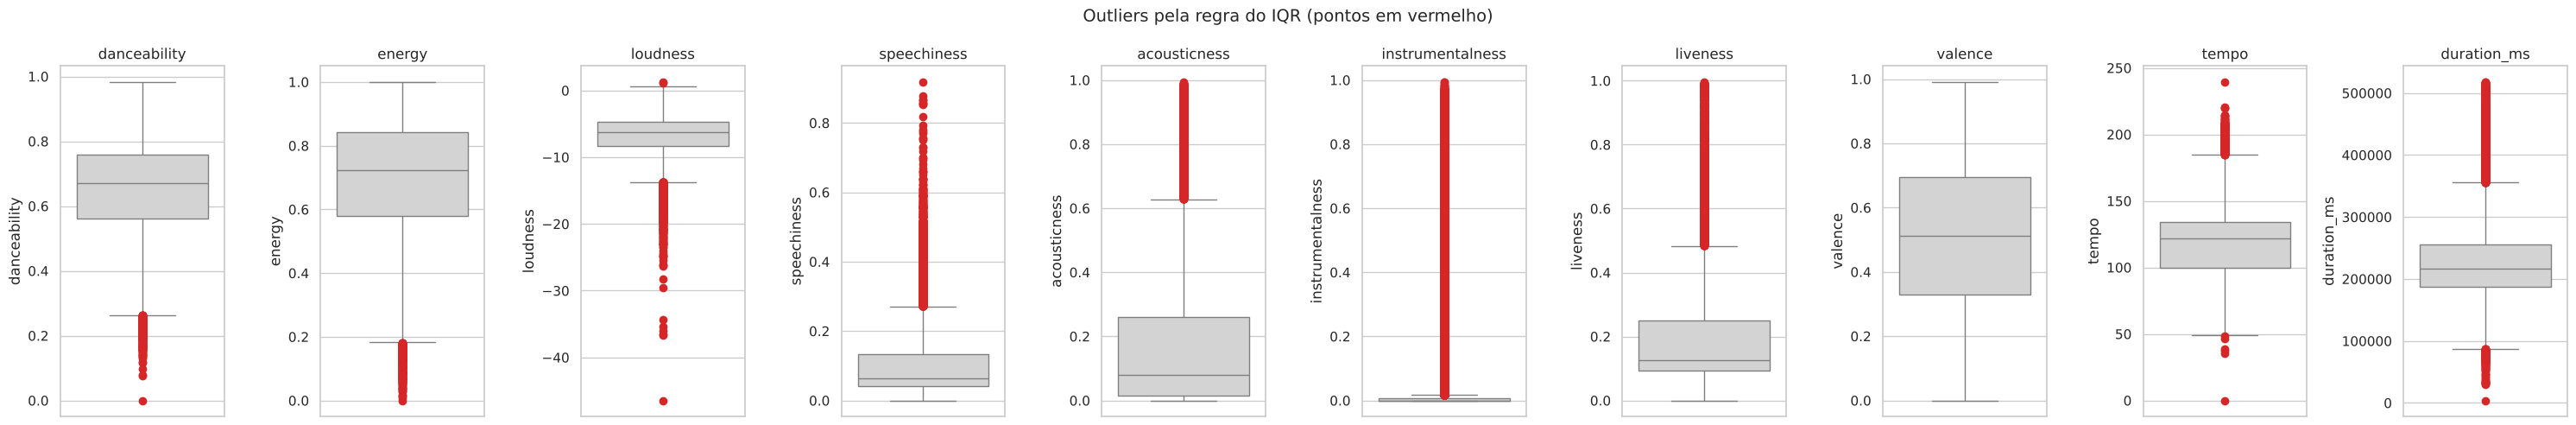

In [23]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(3 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** a aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

*Resposta:*
- **`instrumentalness` (~6 mil "outliers"):** é um efeito da própria regra. Mais da metade das músicas tem valor ~0, então o IQR é quase zero e qualquer faixa com um pouco de parte instrumental vira "outlier". São valores **estatísticos legítimos** (faixas instrumentais e eletrônicas existem), então mantemos.
- **`speechiness`, `liveness`, `acousticness`, `duration_ms`:** caudas longas e plausíveis, como rap muito falado, gravações ao vivo, baladas acústicas, músicas longas e interlúdios curtos. São **estatísticos**, então mantemos.
- **`loudness`:** a cauda baixa (faixas muito silenciosas) é plausível. Há também algumas faixas **acima de 0 dB**, o que é possível em masterizações muito "estouradas" (clipping). São estatísticos e mantemos.
- **`tempo` = 0 BPM:** uma música com andamento zero **viola uma condição física** do domínio. É um outlier **de domínio** e precisa ser investigado (próxima célula).

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável é **MAR** (ausência ligada a músicas com popularidade 0), a ausência está só em colunas de texto que não entram em nenhuma análise numérica, e o volume é de 4 linhas em ~28 mil (~0,01%). A decisão pragmática, como na aula, é **remover as linhas afetadas**. O risco de viés é desprezível.

In [24]:
linhas_antes = df.shape[0]
df_antes = df.copy()
df = df.dropna(subset=cols_com_ausentes).reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 28356 | Linhas depois: 28352 | Removidas: 4


### Decidindo o Tratamento dos Outliers

Como na aula, **não removemos automaticamente**. Quase todos os outliers são **estatísticos** e por isso mantidos. A exceção é o caso de domínio, `tempo` = 0, que investigamos antes de decidir:

In [25]:
df[df["tempo"] == 0][["track_name", "track_artist", "playlist_genre", "tempo", "danceability",
                      "energy", "speechiness", "duration_ms"]]

,track_name,track_artist,playlist_genre,tempo,danceability,energy,speechiness,duration_ms
10638,"Hi, How're You Doin'?",DREAMS COME TRUE,rock,0.0,0.0,0.315,0.0,4000


A faixa com `tempo` = 0 também tem `danceability` = 0, `speechiness` = 0 e dura só 4 segundos, ou seja, a análise de áudio do Spotify não conseguiu extrair o ritmo. Isso é um **erro de dados** (falha na extração), não uma música real com 0 BPM. Como não há como corrigir o valor, removemos essa única linha, a última opção da tabela, mas justificada aqui.

In [26]:
linhas_antes_out = df.shape[0]
df = df[df["tempo"] > 0].reset_index(drop=True)
print(f"Linhas antes: {linhas_antes_out} | Linhas depois: {df.shape[0]} | Removidas: {linhas_antes_out - df.shape[0]}")

Linhas antes: 28352 | Linhas depois: 28351 | Removidas: 1


Os demais outliers ficam como estão. Para ilustrar a opção "transformar", vemos como ficaria uma transformação logarítmica em `duration_ms`, útil caso a assimetria atrapalhe algum teste ou modelo mais à frente.

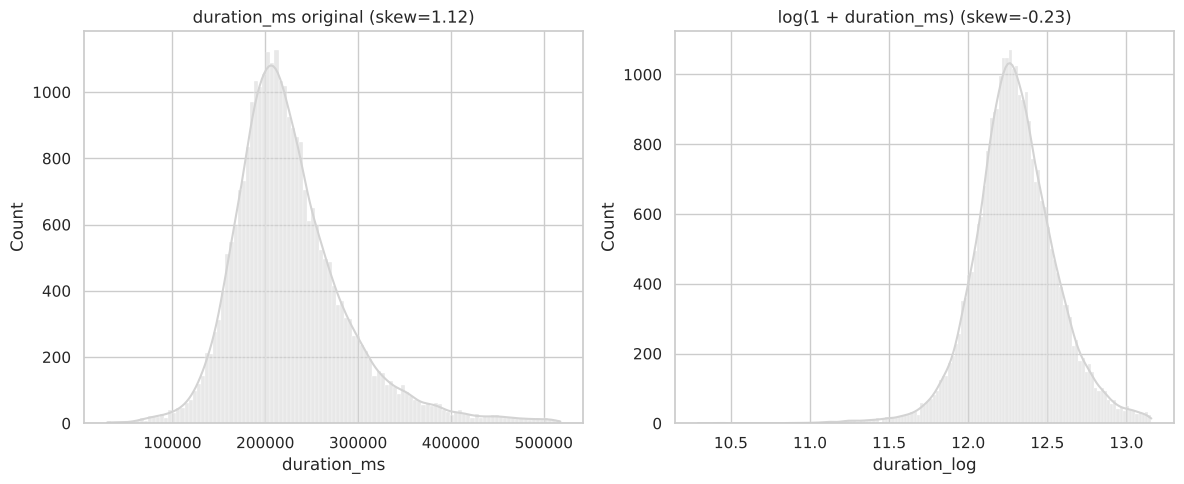

In [27]:
df["duration_log"] = np.log1p(df["duration_ms"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="duration_ms", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"duration_ms original (skew={df['duration_ms'].skew():.2f})")

sns.histplot(data=df, x="duration_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + duration_ms) (skew={df['duration_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu a assimetria? Sim: a cauda direita encolhe, mas surge uma cauda à esquerda, porque o log "estica" os valores pequenos (interlúdios curtos). Mantivemos `duration_log` só como demonstração e **não vamos usá-la** nas próximas seções.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: removemos 4 linhas com ausentes e 1 com erro de extração e mantivemos os demais outliers. Agora rodamos a mesma bateria da Seção 3 para comparar com o "antes".

In [28]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
danceability,0.65,0.67,0.15,0.08,0.98,-0.50,0.01
energy,0.70,0.72,0.18,0.00,1.00,-0.65,-0.01
loudness,-6.82,-6.26,3.03,-46.45,1.27,-1.35,4.54
speechiness,0.11,0.06,0.10,0.02,0.92,1.97,4.27
acousticness,0.18,0.08,0.22,0.00,0.99,1.58,1.78
instrumentalness,0.09,0.00,0.23,0.00,0.99,2.62,5.49
liveness,0.19,0.13,0.16,0.01,1.00,2.08,5.08
valence,0.51,0.51,0.23,0.00,0.99,-0.01,-0.91
tempo,120.96,121.99,26.95,35.48,239.44,0.52,0.07
duration_ms,226582.48,216933.00,61068.13,29493.00,517810.00,1.12,2.54


### Comparando "antes" x "depois"

In [29]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
danceability,-0.506,-0.504,0.016,0.006,0.002,-0.010
energy,-0.645,-0.645,-0.009,-0.009,0.000,0.000
loudness,-1.359,-1.354,4.580,4.544,0.006,-0.036
speechiness,1.965,1.966,4.266,4.269,0.001,0.003
acousticness,1.577,1.576,1.777,1.776,-0.000,-0.001
instrumentalness,2.625,2.625,5.494,5.492,-0.000,-0.002
liveness,2.081,2.082,5.078,5.080,0.000,0.002
valence,-0.007,-0.007,-0.909,-0.909,0.000,-0.000
tempo,0.514,0.517,0.083,0.073,0.003,-0.010
duration_ms,1.115,1.117,2.544,2.542,0.002,-0.002


**Pra discutir:** os valores mudaram muito?

*Resposta:* não. Os deltas ficam na terceira casa decimal, o esperado ao remover 5 linhas em ~28 mil sem mexer nos demais outliers. A pouca mudança confirma que o tratamento foi **conservador**. A única mudança visível é o **mínimo de `tempo`**, que deixa de ser 0. Era exatamente o valor impossível que queríamos eliminar.

**A duração ainda rejeita normalidade?**

Rodamos o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados (mesma estratégia de amostra de 5.000).

In [30]:
amostra_sw_depois = df.sample(5000, random_state=42)
stat_sw_depois, p_valor_sw_depois = stats.shapiro(amostra_sw_depois["duration_ms"].dropna())
print(f"Shapiro-Wilk (antes)  — duration_ms: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — duration_ms: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — duration_ms: estatística=0.9382, p-valor=1.848e-41
Shapiro-Wilk (depois) — duration_ms: estatística=0.9367, p-valor=7.845e-42


Continua rejeitando com folga. A não-normalidade é uma característica da variável, não um efeito das poucas linhas removidas.

**Visualizando antes x depois, lado a lado**

Sobrepomos as distribuições das duas variáveis mais afetadas na Seção 4 (`tempo`, de onde saiu o valor 0, e `duration_ms`), comparando a versão original (`df_antes`) com a tratada (`df`).

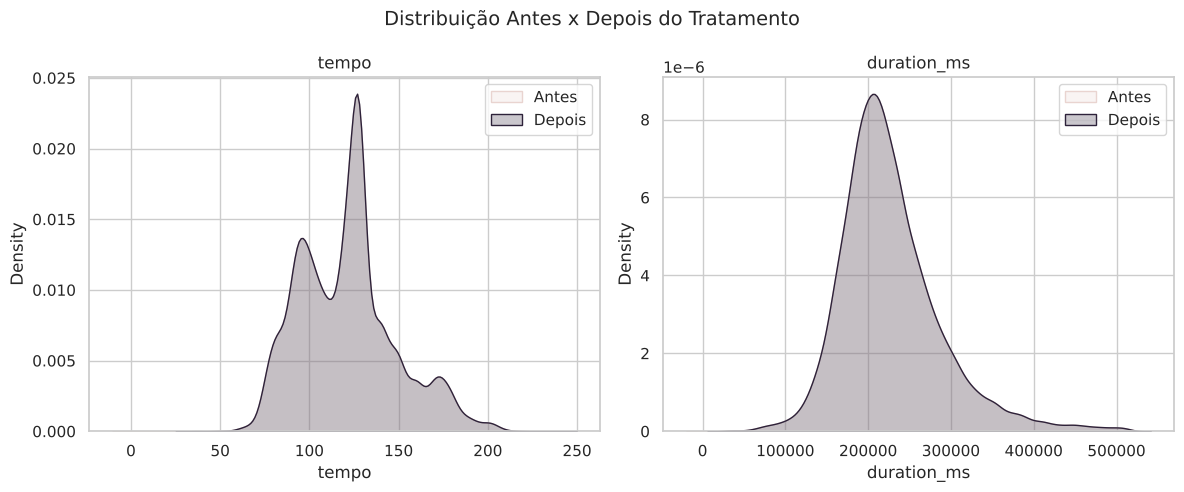

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["tempo", "duration_ms"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Sim. Com 5 linhas removidas em ~28 mil, a diferença é invisível na densidade. A checagem confirma que o tratamento não distorceu as distribuições.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora avaliamos frequência e desbalanceamento das variáveis qualitativas.

#### Frequências absolutas e relativas

In [32]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- playlist_genre ---
                absoluta  relativa
playlist_genre                    
rap                 5398     0.190
pop                 5132     0.181
edm                 4877     0.172
r&b                 4504     0.159
rock                4304     0.152
latin               4136     0.146

--- playlist_subgenre ---
                           absoluta  relativa
playlist_subgenre                            
southern hip hop               1582     0.056
indie poptimism                1547     0.055
neo soul                       1478     0.052
progressive electro house      1460     0.051
electro house                  1416     0.050
gangster rap                   1314     0.046
dance pop                      1298     0.046
hip hop                        1296     0.046
electropop                     1251     0.044
trap                           1206     0.043
hard rock                      1202     0.042
latin hip hop                  1194     0.042
urban contemporary       

#### Visualizando as frequências

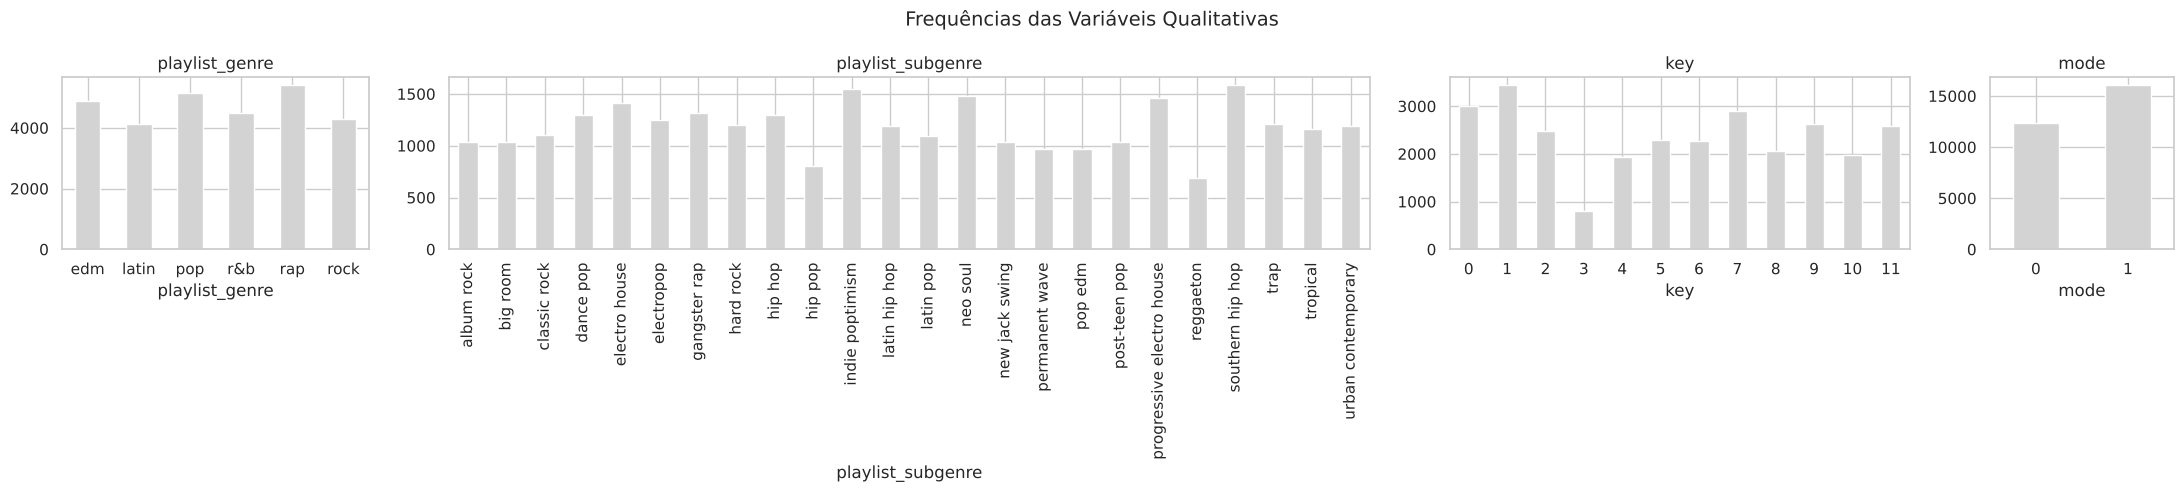

In [33]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5), gridspec_kw={"width_ratios": [1, 3, 1.5, 0.6]})

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=90 if col == "playlist_subgenre" else 0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada?

*Resposta:* não há uma categoria dominando quase tudo. Os 6 gêneros variam entre ~15% e ~19%, porque a coleta buscou playlists por gênero de forma equilibrada. O tom (`key`) tem uma categoria rara: tom 3 (Ré#/Mi♭), com ~3%. `mode` é razoavelmente equilibrado (~57% maior). `playlist_subgenre` tem 24 categorias com contagens parecidas.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento**: # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada**: 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Aplicamos as duas em todas as qualitativas, incluindo o alvo `popularidade_classe`.

In [34]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["popularidade_classe"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
playlist_genre,6.0,1.31,0.997
playlist_subgenre,24.0,2.30,0.994
key,12.0,4.31,0.983
mode,2.0,1.30,0.988
popularidade_classe,2.0,2.90,0.821


**Pra discutir:** alguma variável está com entropia perto de 0? E o alvo está balanceado o suficiente?

*Resposta:* todas as qualitativas têm entropia alta (acima de 0,95), então nenhuma está fortemente desbalanceada. A razão de `key` é a maior, por causa do tom 3, mas a entropia continua alta. O alvo `popularidade_classe` tem razão ~2,9 (74% x 26%), um desbalanceamento **moderado e intencional**, já que definimos "Popular" como o quartil superior. Ele não impede a análise bivariada. Por isso usamos densidade (e não contagem) nos histogramas por classe.

### Análise Bivariada

Agora avaliamos como as variáveis se relacionam entre si e com o alvo `popularidade_classe`.

#### Quantitativa x Quantitativa - Correlação

* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como nenhuma variável passou no Shapiro-Wilk, Spearman é a escolha mais segura, mas calculamos as três para comparar.

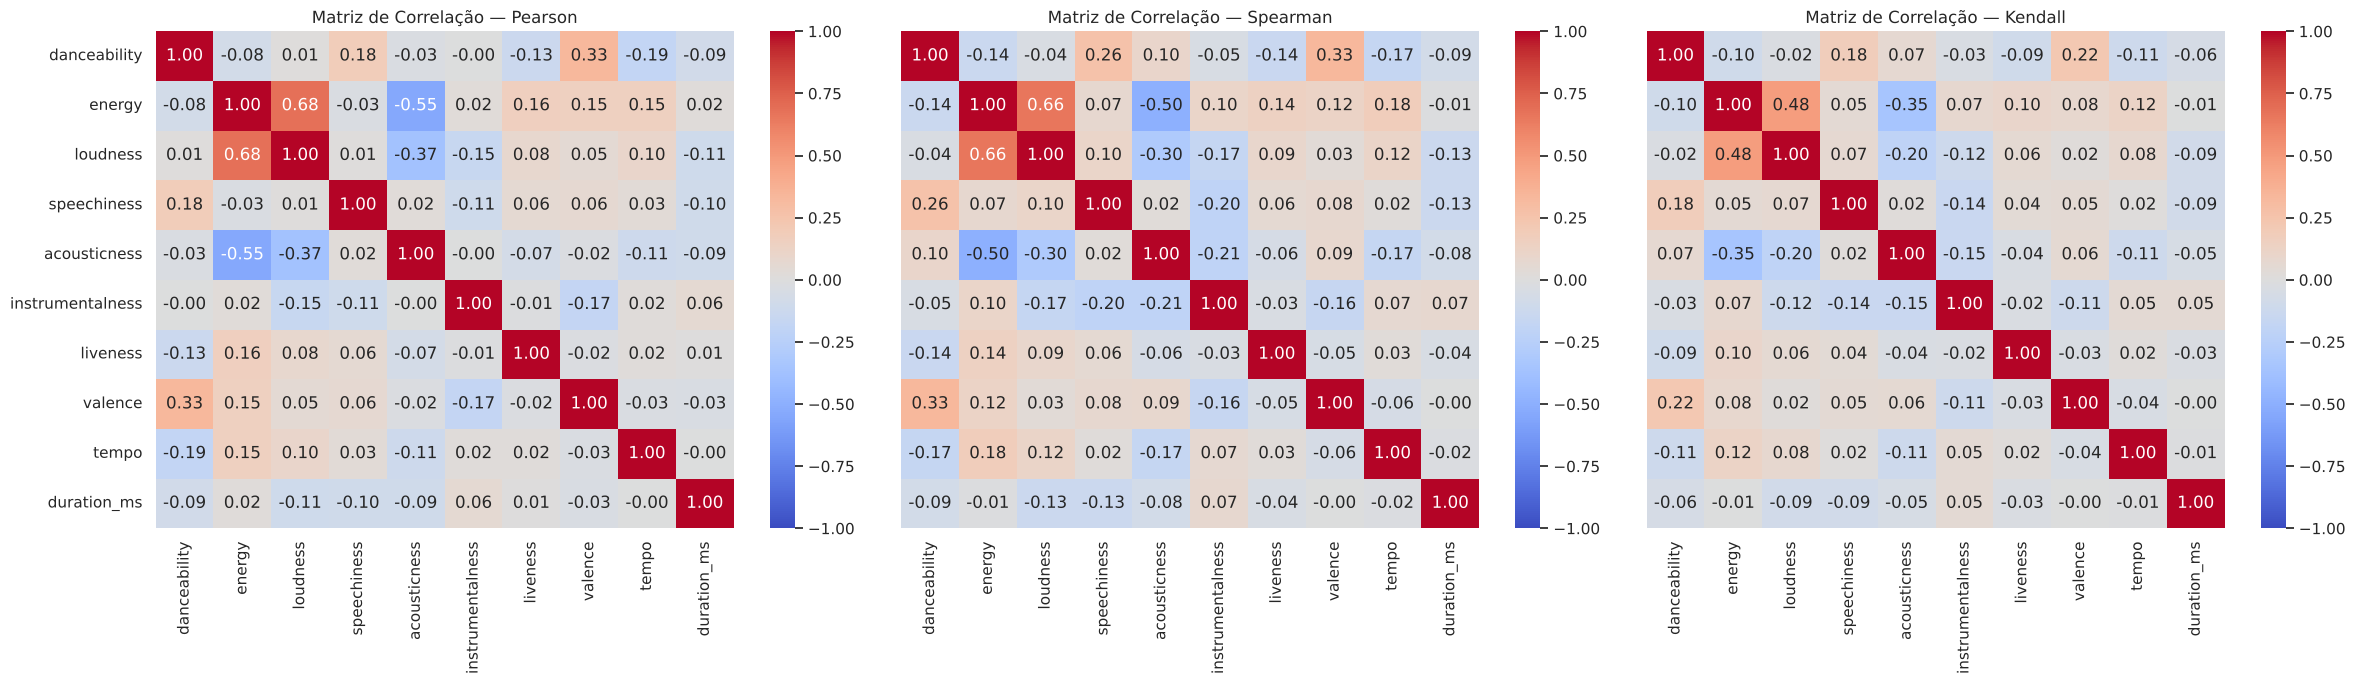

In [35]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(24, 7), sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

Como os triângulos superior e inferior são simétricos, podemos plotar só metade da matriz:

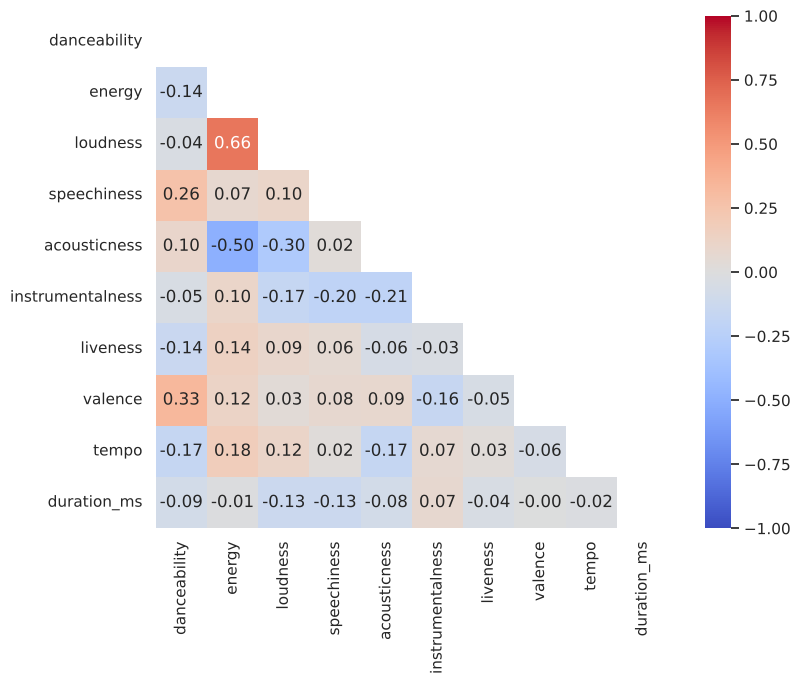

In [36]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par?

*Resposta:* a maior divergência (~0,2) está no par `acousticness` x `instrumentalness`, seguida de outros pares com `acousticness` (como com `danceability`, ~0,13). São justamente as variáveis mais assimétricas e cheias de zeros. Ali a relação é monotônica, mas não linear, e o Pearson é distorcido pela cauda. Nos demais pares os três métodos concordam. Kendall dá valores menores em módulo, o que é normal pela forma como é calculado, mas com o mesmo sinal e a mesma ordem.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `energy` x `loudness` por um motivo de domínio que coincide com a estatística: músicas mais "enérgicas" costumam ser produzidas e masterizadas mais alto, e esse é também o par de maior |correlação| da tabela.

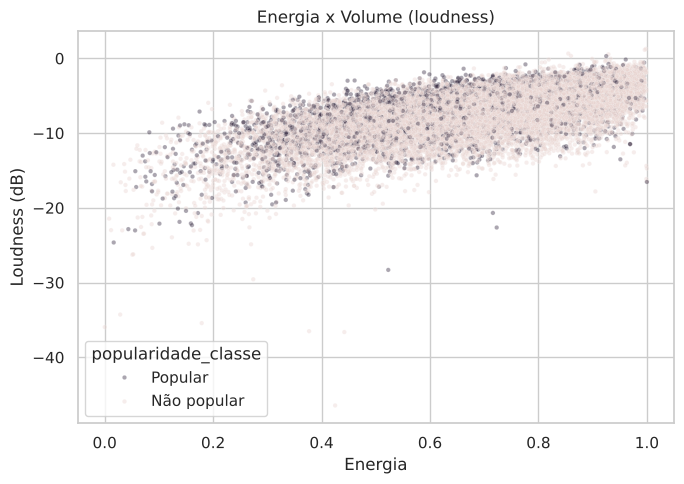

In [37]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="energy", y="loudness", hue="popularidade_classe",
                palette={"Não popular": COR_CONTEXTO, "Popular": COR_DESTAQUE}, alpha=0.4, s=10)
plt.title("Energia x Volume (loudness)")
plt.xlabel("Energia")
plt.ylabel("Loudness (dB)")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível? As classes ocupam regiões diferentes?

*Resposta:* sim, há uma tendência clara e não linear: conforme a energia aumenta, o loudness sobe, e a nuvem se curva e "achata" perto de 0 dB (o teto de volume da masterização). Pearson (0,68) e Spearman (0,66) ficam próximos, porque a curvatura é suave. As duas classes estão **misturadas** na mesma nuvem. A relação energia/volume vale para qualquer música, popular ou não.

#### Quantitativa x Qualitativa: Comparando Grupos

**T-Test** (2 grupos) e **ANOVA** (3+ grupos) assumem normalidade dentro de cada grupo. Como nenhuma variável passou no Shapiro-Wilk, os testes a reportar são os **não-paramétricos**: **Mann-Whitney U** e **Kruskal-Wallis**. Calculamos os dois lado a lado, como na aula.

In [38]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_nao_popular = df.loc[df["popularidade_classe"] == "Não popular", col]
    grupo_popular = df.loc[df["popularidade_classe"] == "Popular", col]

    stat_t, p_t = stats.ttest_ind(grupo_nao_popular, grupo_popular, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_nao_popular, grupo_popular)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "mediana_nao_popular": round(grupo_nao_popular.median(), 3),
        "mediana_popular": round(grupo_popular.median(), 3),
        "p_valor_ttest": p_t,
        "p_valor_mannwhitney": p_u,
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,mediana_nao_popular,mediana_popular,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,,,
danceability,0.667,0.678,7.590350e-08,7.883402e-09,True
energy,0.730,0.700,2.200274e-25,2.598346e-33,True
loudness,-6.368,-5.938,6.862173e-29,1.467964e-27,True
speechiness,0.063,0.062,1.438285e-01,1.364020e-01,True
acousticness,0.071,0.107,5.481869e-16,2.684104e-43,True
instrumentalness,0.000,0.000,1.114149e-191,2.409335e-172,True
liveness,0.129,0.124,8.072819e-12,2.796253e-04,True
valence,0.507,0.528,4.909016e-13,1.500070e-11,True
tempo,122.057,120.080,7.014261e-02,8.854733e-01,True


**Pra discutir:** os dois testes concordam?

*Resposta:* concordam em todas as variáveis. Só `speechiness` e `tempo` **não** diferem entre as classes, e as outras 8 têm diferença estatisticamente significativa. Mas, com ~28 mil músicas, qualquer diferença pequena vira "significativa". As medianas mostram que as diferenças práticas são **pequenas** (por exemplo, `energy` 0,73 x 0,70). O resultado estatístico diz que há diferença, e a magnitude diz que ela é sutil.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`playlist_genre` tem 6 categorias. Comparamos `danceability` entre os gêneros.

ANOVA          — danceability entre gêneros: estatística=1342.861, p-valor=0
Kruskal-Wallis — danceability entre gêneros: estatística=5193.607, p-valor=0


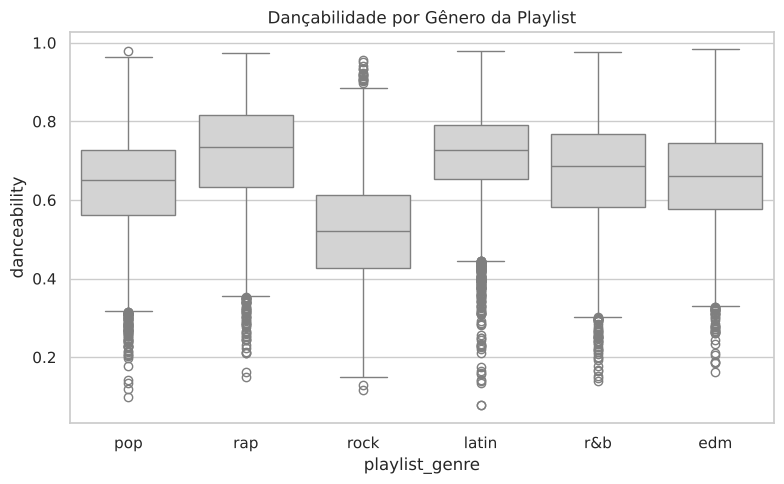

In [39]:
grupos_genero = [grupo["danceability"].values for _, grupo in df.groupby("playlist_genre")]

stat_anova, p_anova = stats.f_oneway(*grupos_genero)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_genero)          # não-paramétrico

print(f"ANOVA          — danceability entre gêneros: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — danceability entre gêneros: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="playlist_genre", y="danceability", color=COR_NEUTRA)
plt.title("Dançabilidade por Gênero da Playlist")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA?

*Resposta:* sim. Os dois rejeitam a igualdade com p-valor praticamente zero. Aqui a diferença é grande também na prática: **rap** e **latin** têm as maiores medianas de dançabilidade (~0,73), e **rock** fica bem abaixo (~0,52). Diferente da popularidade, o **gênero** separa bem as características de áudio.

#### Qualitativa x Qualitativa

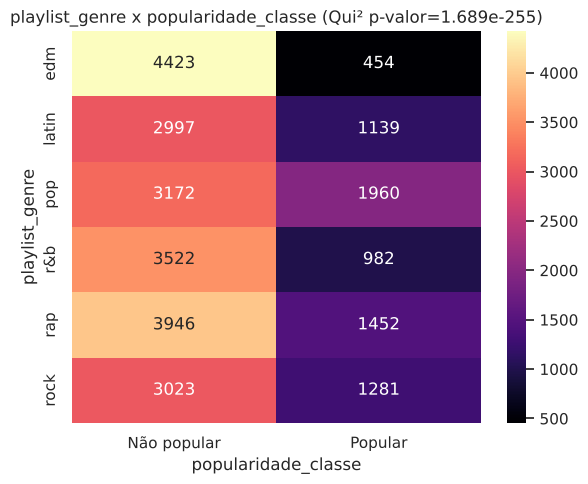

In [40]:
contingencia_genero = pd.crosstab(df["playlist_genre"], df["popularidade_classe"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_genero)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_genero, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"playlist_genre x popularidade_classe (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica independência ou associação?

*Resposta:* há **associação significativa** (p-valor ≈ 0). O gênero está fortemente ligado à chance de a música estar no quartil mais popular, como mostra a seção de fairness logo abaixo.

#### Avaliação de Fairness

Na aula, a pergunta foi: a distribuição do desfecho se comporta igual em diferentes subgrupos de **atributos sensíveis** (sexo, faixa etária)?

**Adaptação justificada:** o Spotify Songs **não tem atributos sensíveis de pessoas** (não há sexo, idade ou etnia de artistas ou ouvintes). Aplicamos a mesma pergunta aos subgrupos que podem carregar **viés de coleta**: o **gênero da playlist** e a **época de lançamento** (o equivalente à faixa etária da aula, criada a partir do ano de lançamento).

In [41]:
df["ano_lancamento"] = pd.to_numeric(df["track_album_release_date"].str[:4], errors="coerce")
df["epoca_lancamento"] = pd.cut(df["ano_lancamento"], bins=[0, 1999, 2009, 2016, 2100],
                                 labels=["até 1999", "2000-2009", "2010-2016", "2017-2020"])

print("Desbalanceamento — gênero:")
print(metrica_desbalanceamento(df["playlist_genre"]))
print("\nDesbalanceamento — época de lançamento:")
print(metrica_desbalanceamento(df["epoca_lancamento"]))

Desbalanceamento — gênero:
n_classes                 6.000
razao_desbalanceamento    1.310
entropia_normalizada      0.997
dtype: float64

Desbalanceamento — época de lançamento:
n_classes                 4.000
razao_desbalanceamento    3.440
entropia_normalizada      0.906
dtype: float64


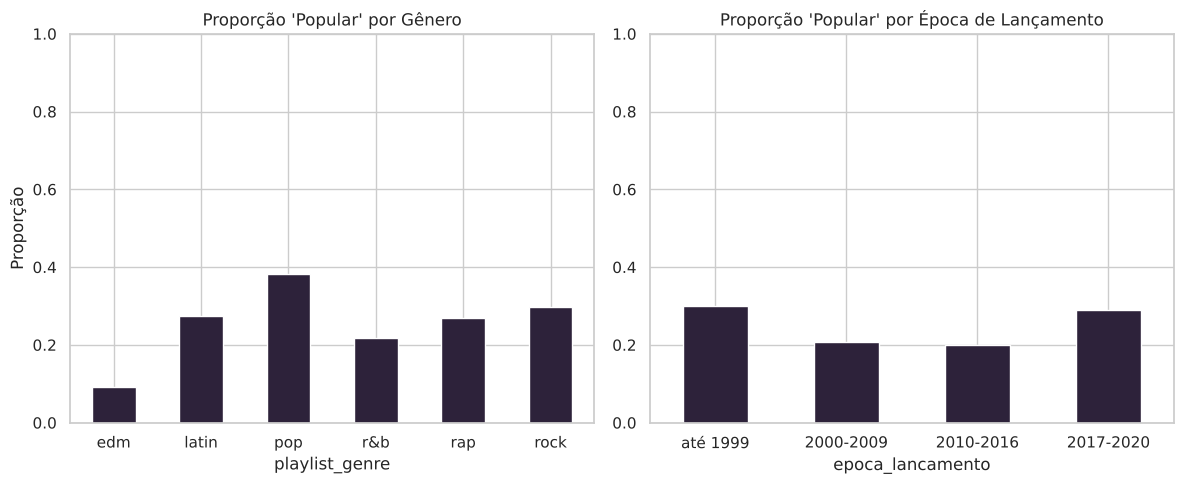

In [42]:
prop_por_genero = pd.crosstab(df["playlist_genre"], df["popularidade_classe"], normalize="index").round(3)
prop_por_epoca = pd.crosstab(df["epoca_lancamento"], df["popularidade_classe"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_genero["Popular"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Popular' por Gênero")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_epoca["Popular"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Popular' por Época de Lançamento")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de "Popular" varia bastante entre gênero ou época?

*Resposta:* varia bastante por **gênero**: ~38% das músicas de **pop** estão no quartil popular, contra só ~9% de **edm**. Por **época** aparece um formato em "U": as músicas até 1999 e as de 2017-2020 têm mais populares (~29-30%) do que as de 2000-2016 (~20%). Duas explicações possíveis, que os dados sozinhos não separam:
- **Padrão real:** a popularidade do Spotify é calculada sobre execuções **recentes**, o que favorece lançamentos novos.
- **Viés de coleta:** músicas antigas só entram em playlists atuais se forem **clássicos** (viés de sobrevivência), e a busca por playlists de cada gênero pode ter puxado playlists mais ou menos populares.

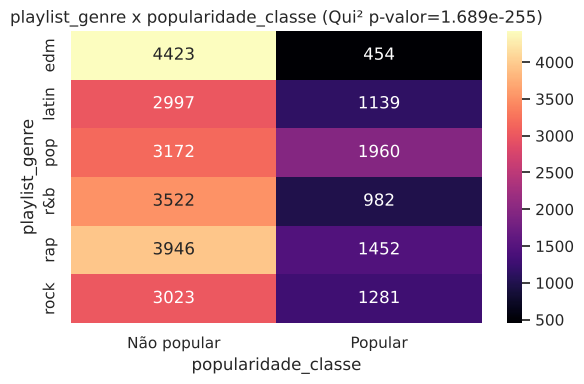

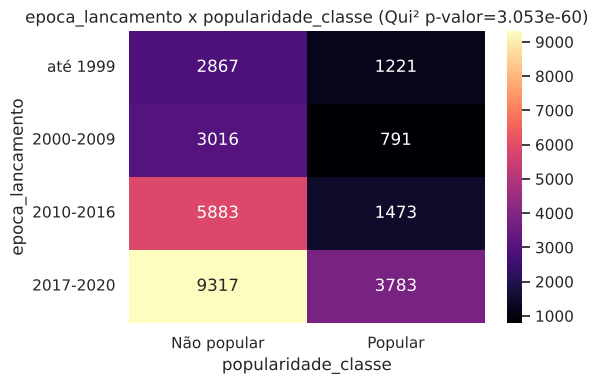

In [43]:
for atributo in ["playlist_genre", "epoca_lancamento"]:
    contingencia = pd.crosstab(df[atributo], df["popularidade_classe"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x popularidade_classe (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação?

*Resposta:* sim, nos dois casos (p-valor praticamente zero). Como discutido em sala, o teste aponta **que** existe associação, não **por que**. Aqui, comparar a popularidade de músicas de gêneros ou épocas diferentes sem considerar esse contexto levaria a conclusões injustas, como dizer que "edm é ruim" quando pode ser um efeito de quais playlists de edm foram coletadas.

#### Outliers bivariados

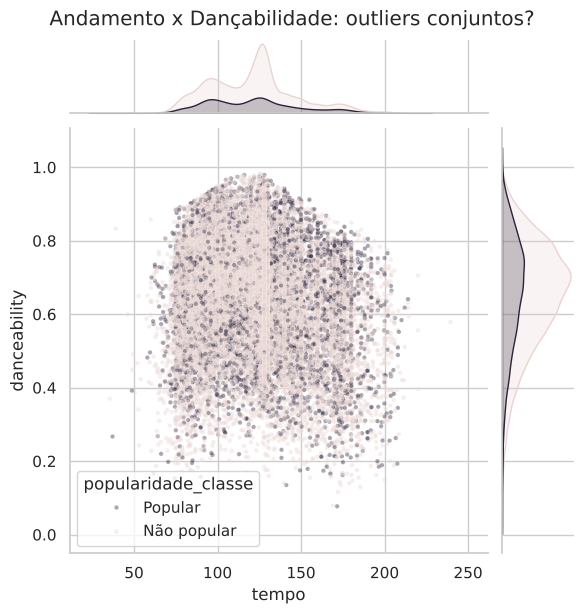

In [44]:
sns.jointplot(data=df, x="tempo", y="danceability", hue="popularidade_classe",
              palette={"Não popular": COR_CONTEXTO, "Popular": COR_DESTAQUE}, alpha=0.4, s=10, height=6)
plt.suptitle("Andamento x Dançabilidade: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados, mas que se destaca aqui como uma combinação incomum?

*Resposta:* sim. Andamentos altos (~150-200 BPM) não são raros sozinhos, e dançabilidade baixa (< 0,3) também não. A **combinação** dos dois aparece em poucos pontos isolados abaixo da nuvem principal (pouco mais de 100 músicas com tempo > 170 e dançabilidade < 0,3). Provavelmente são faixas muito rápidas e irregulares, ou faixas em que a análise detectou o dobro do andamento real. Também se destacam alguns pontos isolados com andamento muito baixo (< 60 BPM). A nuvem tem ainda uma "linha" vertical perto de 125 BPM, o andamento típico de músicas eletrônicas de pista.

#### Análise Multivariada

##### Matriz de Correlação

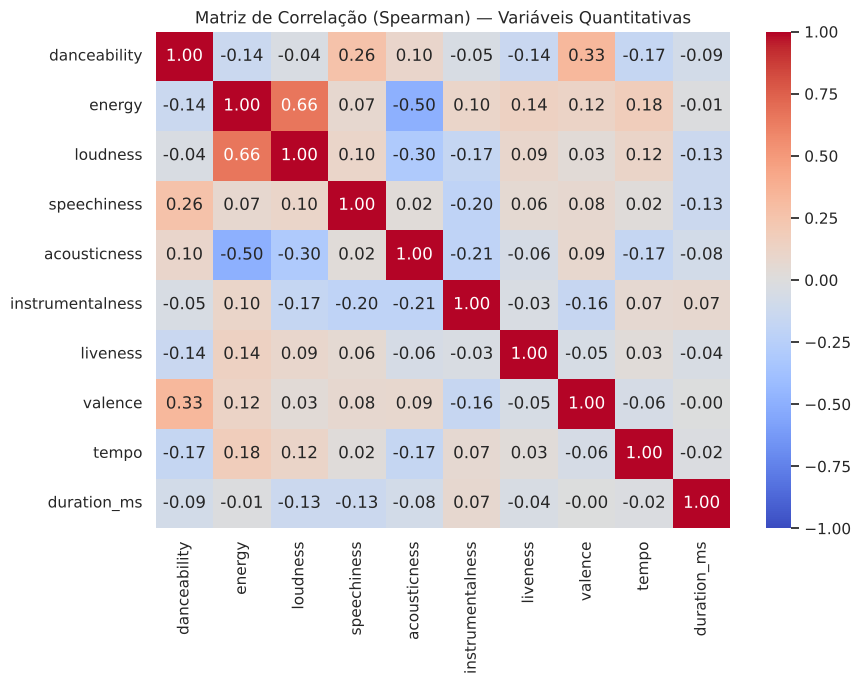

In [45]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

**Como interpretar:**

*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

**Alguma correlação sugere redundância?** Nenhum par passa de 0,7, então não há redundância forte. As moderadas são `energy` x `loudness` (+0,66), `energy` x `acousticness` (−0,50), `danceability` x `valence` (+0,33) e `loudness` x `acousticness` (−0,30). Elas formam um eixo "intensidade" (energia, volume e pouca acústica). Todo o resto é fraco: cada característica de áudio carrega informação própria.

##### Correlograma

*Adaptação:* com 10 variáveis e ~28 mil pontos, o `PairGrid` fica muito pesado. Plotamos tudo em uma **amostra aleatória de 2.000 músicas**. Os círculos usam `np.corrcoef` (Pearson), como na aula, calculado nessa amostra. Por isso os valores podem diferir um pouco da matriz de Spearman acima.

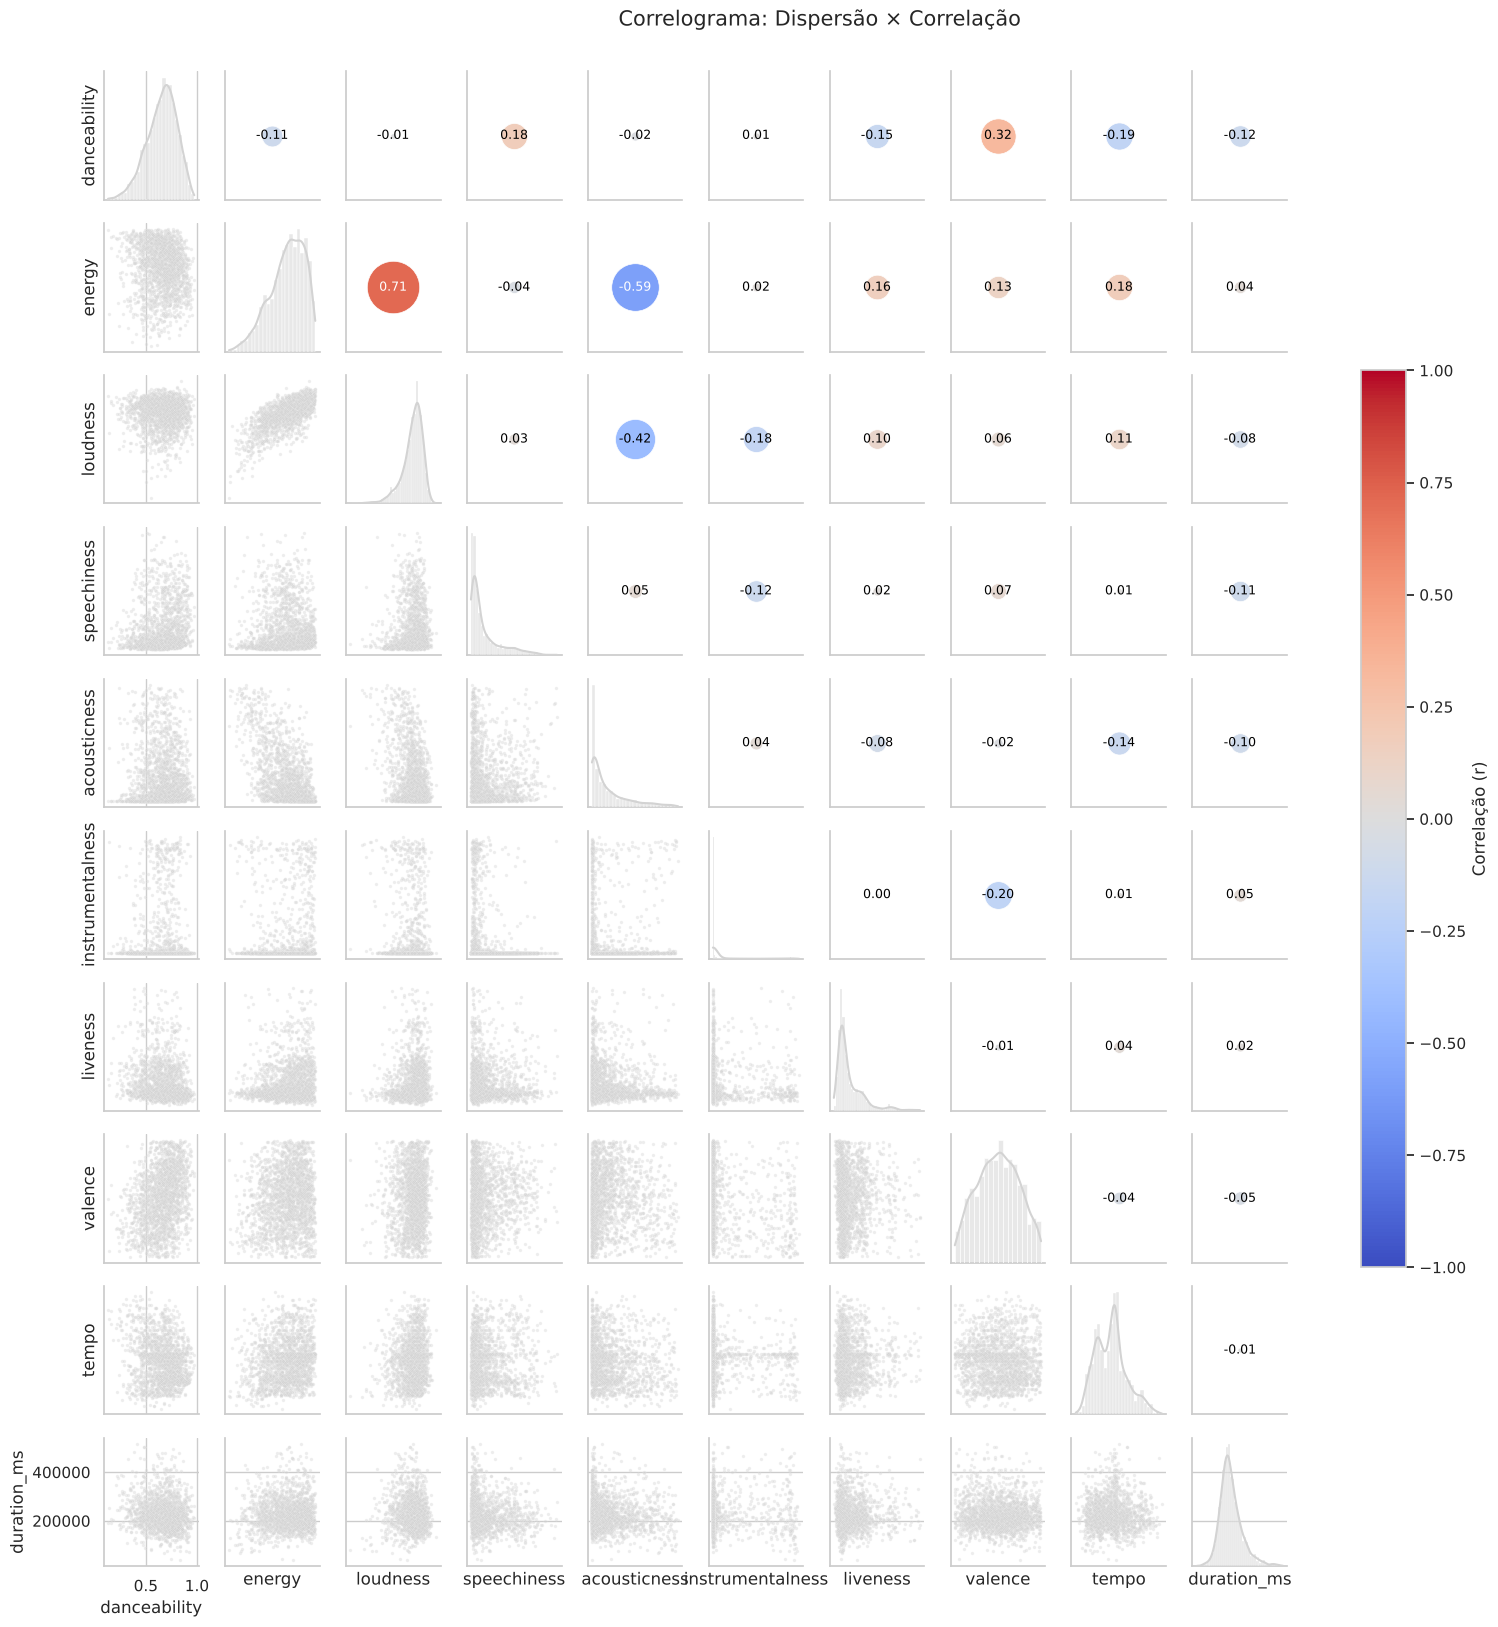

In [46]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 2000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=9,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

amostra_corr = df[VARS_QUANT].sample(2000, random_state=42)

g = sns.PairGrid(amostra_corr, diag_sharey=False, height=1.6)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.4, s=6)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)
plt.show()

---
> 🆕 **NOVA SEÇÃO (não estava no notebook da EDA entregue)**: as 4 células abaixo (esta, mais 3) servem apenas para salvar os datasets em disco para o app Streamlit.

## 🆕 Download dos Datasets

Vamos salvar duas versões do dataset:

- `data/raw/dataset.csv`: o dataset **original**, como veio do TidyTuesday (32.833 linhas, com as músicas repetidas entre playlists).
- `data/clean/dataset.csv`: o dataset **tratado**, no estado final do `df` ao longo da EDA (uma linha por `track_id`, sem as 4 músicas sem metadados e sem a faixa com `tempo` = 0, com as colunas derivadas `popularidade_classe`, `duration_log`, `ano_lancamento` e `epoca_lancamento`). É este arquivo que o `app.py` lê.

> Rode o notebook **do início ao fim** antes desta seção, para que o `df` esteja no estado final.

In [47]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [48]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL (lido de novo da fonte, sem nenhum tratamento)
df_raw = pd.read_csv(DATA_URL)
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

Raw salvo em ../data/raw/dataset.csv — 32833 linhas x 23 colunas


In [49]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")

Clean salvo em ../data/clean/dataset.csv — 28351 linhas x 27 colunas
Linhas removidas no tratamento: 4482


## Síntese

### Principais conclusões

1. **Estrutura:** o arquivo original tem 32.833 linhas, mas só ~28,3 mil músicas distintas. 4.477 linhas eram a mesma música repetida em várias playlists, e deduplicar por `track_id` foi a decisão mais importante da limpeza. Os ausentes eram mínimos (4 músicas sem metadados, todas com popularidade 0, provável MAR) e foram removidos. Removemos também 1 erro de extração (`tempo` = 0).
2. **Distribuições:** nenhuma característica de áudio é normal. `instrumentalness`, `liveness`, `speechiness` e `acousticness` são concentradas perto de zero com cauda longa, e `loudness` se acumula perto do teto de 0 dB. Os outliers são, quase todos, valores legítimos do domínio. Por isso usamos Spearman e testes não-paramétricos.
3. **Popularidade x áudio:** as diferenças entre músicas populares e não populares são estatisticamente significativas em 8 de 10 variáveis, mas **pequenas na prática**. As populares têm um pouco menos de energia e um pouco mais de volume e acústica. As características de áudio, sozinhas, explicam pouco o sucesso.
4. **Gênero importa muito:** o gênero separa bem o "som" (a dançabilidade do rock é bem menor que a do rap e do latin) e está fortemente associado à popularidade (~38% de populares no pop contra ~9% no edm).
5. **Viés:** a proporção de populares varia por gênero e por época em formato de "U". Isso pode refletir o cálculo de popularidade do Spotify (que favorece execuções recentes) e a forma de coleta por playlists (viés de sobrevivência dos clássicos). Comparações de popularidade devem sempre ser feitas **dentro** do mesmo gênero e época.

### Declaração de Uso de IA

| Campo | Resposta |
|---|---|
| **Ferramenta utilizada** | Claude (Anthropic) |
| **Para o que foi aplicada** | (1) Avaliar o dataset escolhido inicialmente (One Piece, do Kaggle) e sugerir uma alternativa com mais variáveis quantitativas; (2) adaptar o código do notebook da Aula 11 (Heart Disease) para o dataset Spotify Songs; (3) rascunhar as respostas das perguntas de discussão e a síntese a partir dos resultados executados. |
| **O que foi aceito** | A troca de dataset para o Spotify Songs; a estrutura de código da aula adaptada às novas variáveis; as decisões de tratamento (deduplicar por `track_id`, remover as 4 linhas sem metadados e a linha com `tempo` = 0), conferidas com os resultados das células. |
| **O que foi modificado** | Adaptações ao dataset, justificadas no próprio notebook: Shapiro-Wilk em amostra de 5.000 (limite do teste), histogramas por classe em densidade (classes de tamanhos diferentes), correlograma em amostra de 2.000 pontos (desempenho) e fairness aplicada a gênero/época, já que o dataset não tem atributos sensíveis de pessoas. |
| **O que foi rejeitado e por quê** | Manter o dataset One Piece: das 57 colunas, 54 são texto e a maioria está quase toda vazia, o que deixaria a EDA quantitativa e os dashboards da próxima atividade muito limitados. |